# 04 — Volatility checking

Every model in this project predicts `logvol_after` and uses `logvol_before` as the baseline, so before modelling we check those labels are good.

Kogan et al. (2009) took each company's daily share returns from the Center for Research in Security Prices (CRSP) over the 12 months before and after the filing date,
took their standard deviation, and then the natural log. So `logvol = log(sd of daily returns)`. 

We already showed in `01-Planning.ipynb` that recomputing the 2004 labels from Yahoo prices gives almost the same numbers (correlation 0.99).
Here we check the rest:

1. Are the raw files complete (every report has a before label, an after label and a meta line)?
2. Where a report is listed twice, do the copies agree?
3. Does `dataset.csv` (what the models use) hold exactly the raw labels?
4. Are the values in a believable range, with no placeholders? And what explains the most extreme ones (4a)?

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path("..")
PROCESSED = ROOT / "data" / "processed"
kogan_dir = ROOT / "data" / "raw" / "kogan"
YEARS = range(1996, 2007)

## 1. Read the raw label files

Each year has two files, `logvol.-12` (12 months before filing) and `logvol.+12` (12 months after), each a list of `value key` lines,
plus `meta.txt` with the filing date, name and CIK.

In [2]:
def read_logvol(year, which):
    return pd.read_csv(kogan_dir / f"{year}.logvol.{which}12.txt", sep=" ", header=None, names=["logvol", "key"])

raw = []
for y in YEARS:
    before, after = read_logvol(y, "-"), read_logvol(y, "+")
    meta = pd.read_csv(kogan_dir / f"{y}.meta.txt", sep="\t", header=None, names=["key", "date", "url", "name", "cik"])
    raw.append(pd.DataFrame({"year": y, "rows_before": len(before), "rows_after": len(after), "rows_meta": len(meta),
                             "keys_before": before["key"].nunique(), "keys_after": after["key"].nunique(),
                             "same_keys": set(before["key"]) == set(after["key"]) == set(meta["key"])}, index=[0]))
pd.concat(raw, ignore_index=True)

,year,rows_before,rows_after,rows_meta,keys_before,keys_after,same_keys
0,1996,1408,1408,1408,1406,1406,True
1,1997,2260,2260,2260,2260,2260,True
2,1998,2462,2462,2462,2461,2461,True
3,1999,2524,2524,2524,2524,2524,True
4,2000,2425,2425,2425,2424,2424,True
5,2001,2596,2596,2596,2596,2596,True
6,2002,2846,2846,2846,2845,2845,True
7,2003,3612,3612,3612,3611,3611,True
8,2004,3559,3559,3559,3558,3558,True
9,2005,3474,3474,3474,3474,3474,True


- `rows_*` vs `keys_*`: if a file has more rows than distinct keys, some reports are listed twice (we already knew this from 01).
- `same_keys`: every report should have a before label, an after label and a meta line.

## 2. Duplicated reports: do the repeats agree?

A repeated key is harmless if both copies have the same value, but could be a real problem if they disagree.

In [3]:
def all_labels(which):
    return pd.concat([read_logvol(y, which).assign(year=y) for y in YEARS], ignore_index=True)

for which, label in [("-", "before"), ("+", "after")]:
    lab = all_labels(which)
    dup = lab[lab.duplicated("key", keep=False)]
    conflicting = dup.groupby("key")["logvol"].nunique().gt(1).sum()
    print(f"logvol {label}: {len(lab):,} rows, {lab['key'].nunique():,} distinct reports, "
          f"{dup['key'].nunique():,} repeated, {conflicting} with conflicting values")

logvol before: 30,474 rows, 30,465 distinct reports, 9 repeated, 0 with conflicting values
logvol after: 30,474 rows, 30,465 distinct reports, 9 repeated, 0 with conflicting values


## 3. Does `dataset.csv` hold exactly the raw labels?

`dataset.csv` is what the models load. Its labels came through two merges (`02-Merge-Kogan-EDGAR.ipynb` and `build_dataset.py`),
so we check nothing got shifted onto the wrong report on the way.

In [4]:
df = pd.read_csv(PROCESSED / "dataset.csv", parse_dates=["date"])
print(f"dataset.csv: {len(df):,} reports, keys unique: {df['key'].is_unique}")

raw_before = all_labels("-").drop_duplicates("key").set_index("key")["logvol"]
raw_after = all_labels("+").drop_duplicates("key").set_index("key")["logvol"]

check = pd.DataFrame({
    "before_matches_raw": np.isclose(df["logvol_before"], df["key"].map(raw_before)),
    "after_matches_raw": np.isclose(df["logvol_after"], df["key"].map(raw_after)),
    "year_matches_date": df["year"] == df["date"].dt.year,
})
check.mean().map("{:.2%}".format)

dataset.csv: 27,142 reports, keys unique: True


before_matches_raw    100.00%
after_matches_raw     100.00%
year_matches_date     100.00%
dtype: str

The key itself ends in the filing date, so we can also check the date column agrees with it. Note Kogan's key format changes
partway through 2001: older keys end `...-10-K-19960401`, newer ones `...-10-K-2001-07-30`. `key_date` handles both.

In [5]:
def key_date(keys):
    """Filing date from a Kogan key, in either format (19960401 or 2001-07-30)."""
    digits = keys.str.extract(r"(\d{4}-?\d{2}-?\d{2})$")[0].str.replace("-", "")
    return pd.to_datetime(digits, format="%Y%m%d")

print(f"date column equals the date in the key: {(key_date(df['key']) == df['date']).mean():.2%}")

date column equals the date in the key: 100.00%


## 4. Are the values believable?

We look for:
- missing or infinite values
- the range
- values repeated suspiciously often (a sign of a filler value)
- most extreme reports.

In [6]:
def to_annual(logvol):
    """log daily s.d. -> annualised volatility, as a fraction (0.4 = 40%)."""
    return np.exp(logvol) * np.sqrt(252)

for col in ["logvol_before", "logvol_after"]:
    v = df[col]
    print(f"{col}: missing {v.isna().sum()}, infinite {np.isinf(v).sum()}, "
          f"range {v.min():.2f} to {v.max():.2f} "
          f"(annualised {to_annual(v.min()):.0%} to {to_annual(v.max()):.0%}), "
          f"median {v.median():.2f} ({to_annual(v.median()):.0%} a year)")

print("\nmost repeated values of logvol_after:")
print(df["logvol_after"].round(6).value_counts().head(5))

logvol_before: missing 0, infinite 0, range -5.17 to -0.24 (annualised 9% to 1249%), median -3.39 (53% a year)
logvol_after: missing 0, infinite 0, range -7.92 to -0.27 (annualised 1% to 1212%), median -3.45 (50% a year)

most repeated values of logvol_after:
logvol_after
-3.421935    3
-3.653698    3
-3.897736    3
-4.361722    3
-3.975709    3
Name: count, dtype: int64


It is worth pausing to consider if a volatility ~50% a year sensible? A single company should be much more volatile than the market index, because its own news doesn't average out across hundreds of firms (Campbell et al., 2001). The market index itself has
historically been far calmer, rising sharply only in crises.

We now run a quick sense check on our own data with this in mind. For every report we compute the S&P 500's volatility over the same 12 months after filing, with
the same formula as Kogan's labels (log of the s.d. of daily log returns), using index prices from Yahoo (`^GSPC`).

- Campbell, J. Y., Lettau, M., Malkiel, B. G. & Xu, Y. (2001). Have individual stocks become more volatile? An empirical exploration of idiosyncratic risk. *Journal of Finance*, 56(1), 1–43.

In [7]:
sp_file = PROCESSED / "sp500_prices.pkl"
if sp_file.exists():
    sp = pd.read_pickle(sp_file)
else:
    import yfinance as yf
    # to Jan 2008: a filing in late 2006 needs prices up to late 2007
    sp = yf.download("^GSPC", start="1996-01-01", end="2008-01-31", auto_adjust=True, progress=False)["Close"].squeeze()
    sp.to_pickle(sp_file)
sp_returns = np.log(sp).diff().dropna()

def index_logvol(filed):
    """Log s.d. of the S&P 500's daily log returns in the 12 months after `filed` (same formula as Kogan)."""
    window = sp_returns[(sp_returns.index > filed) & (sp_returns.index <= filed + pd.DateOffset(years=1))]
    return np.log(window.std())

# many reports share a filing date, so compute each date once
by_date = pd.Series({d: index_logvol(d) for d in df["date"].unique()})
df["sp500_logvol_after"] = df["date"].map(by_date)

compare = df.groupby("year")[["logvol_after", "sp500_logvol_after"]].median()
compare["firm_annual"] = to_annual(compare["logvol_after"])
compare["sp500_annual"] = to_annual(compare["sp500_logvol_after"])
compare["firm_over_index"] = compare["firm_annual"] / compare["sp500_annual"]
print(f"over all reports: median firm {to_annual(df['logvol_after'].median()):.0%} a year, "
      f"S&P 500 over the same windows {to_annual(df['sp500_logvol_after'].median()):.0%}")
compare[["firm_annual", "sp500_annual", "firm_over_index"]].style.format(
    {"firm_annual": "{:.0%}", "sp500_annual": "{:.0%}", "firm_over_index": "{:.1f}x"})

over all reports: median firm 50% a year, S&P 500 over the same windows 17%


,firm_annual,sp500_annual,firm_over_index
year,,,
1996,53%,13%,4.1x
1997,56%,18%,3.1x
1998,70%,22%,3.2x
1999,76%,19%,3.9x
2000,79%,22%,3.6x
2001,66%,20%,3.4x
2002,63%,27%,2.3x
2003,46%,14%,3.4x
2004,39%,11%,3.6x


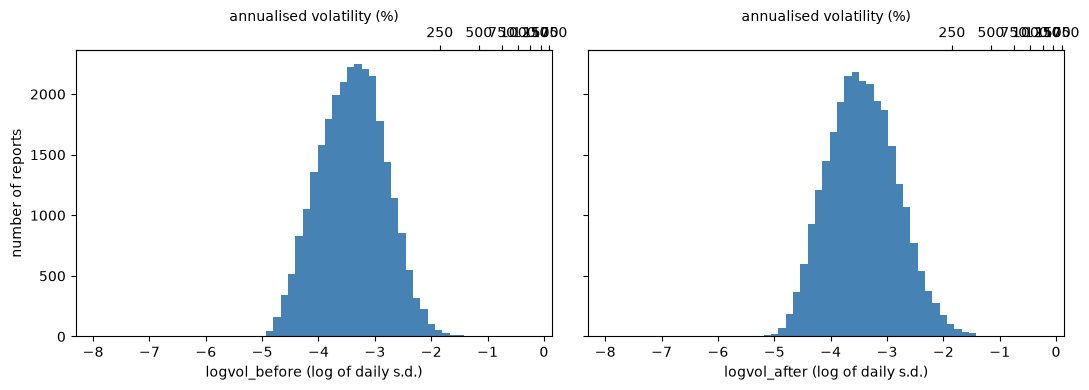

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
bins = np.linspace(min(df["logvol_before"].min(), df["logvol_after"].min()),
                   max(df["logvol_before"].max(), df["logvol_after"].max()), 60)
for ax, col in zip(axes, ["logvol_before", "logvol_after"]):
    ax.hist(df[col], bins=bins, color="steelblue")
    ax.set_xlabel(f"{col} (log of daily s.d.)")
    top = ax.secondary_xaxis("top", functions=(lambda x: np.exp(x) * np.sqrt(252) * 100,
                                               lambda a: np.log(np.maximum(a, 1e-9) / 100 / np.sqrt(252))))
    top.set_xlabel("annualised volatility (%)")
axes[0].set_ylabel("number of reports")
plt.tight_layout()
plt.show()

In [9]:
cols = ["name", "date", "logvol_before", "logvol_after"]
lowest = df.nsmallest(5, "logvol_after")[cols]
highest = df.nlargest(5, "logvol_after")[cols]
pd.concat([lowest, highest]).assign(annual_after=lambda d: to_annual(d["logvol_after"]).map("{:.0%}".format))

,name,date,logvol_before,logvol_after,annual_after
3789,DEKALB GENETICS CORP,1998-11-30,-3.074297,-7.924972,1%
11265,ODWALLA INC,2001-11-29,-3.054124,-7.337001,1%
26861,UICI,2006-03-14,-3.987242,-6.952648,2%
19063,GROUP 1 SOFTWARE INC,2004-06-14,-3.357658,-6.799888,2%
24362,ARAMARK CORP/DE,2006-11-22,-4.210584,-6.777078,2%
4613,OIS OPTICAL IMAGING SYSTEMS INC,1998-12-10,-1.471502,-0.269498,1212%
8669,IWERKS ENTERTAINMENT INC,2000-09-28,-2.535755,-0.645265,833%
14099,SALON MEDIA GROUP INC,2002-06-26,-1.435805,-0.744353,754%
12802,EMAGIN CORP,2002-04-01,-2.223755,-0.781472,727%
3690,COMMERCE GROUP CORP /WI/,1998-06-29,-2.754122,-1.005355,581%


### 4a. Examining every extreme report - Claude

The table above shows a handful of very extreme values. Here we look at **every** extreme report, one by one, and ask what happened to the company.

- **Very low:** `logvol_after` below −5, i.e. under about 11% a year. Calmer than the whole S&P 500 in most years, which is strange for a single company.
- **Very high:** `logvol_after` above −1.5, i.e. over about 350% a year: the price regularly moves 20% or more in a day.

**Two things we expect to find:**

1. **Takeovers make volatility collapse.** Suppose Monsanto agrees to pay \$40 cash per share for DEKALB. From then until the deal closes,
   DEKALB's shares trade just under \$40 whatever the market does, because every shareholder knows what they will receive. The price
   barely moves, so measured volatility is close to zero. The company is not "safe"; it is about to stop existing.
2. **Distress makes volatility explode.** When a company might go bankrupt, its shares are worth either almost nothing or much more,
   and every piece of news swings the price. Its share price is often very low too, and a move from 5 cents to 10 cents is +100% in a day.

**Evidence we collect for each report** (from EDGAR-CORPUS, which has about 9,000 filings a year, more than Kogan's set):

- `files_next_year`: does the same company (CIK) file a 10-K the following year? If not, it probably stopped being a listed company,
  through a takeover or a failure. Unknown for 2006 filings, because our EDGAR data stops in 2006.
- `takeover`: does the report's own text (Items 1 and 7) contain takeover wording: *agreement and plan of merger*, *merger agreement*,
  *tender offer*, *going private*, *will become a wholly owned subsidiary*?
- `distress`: does it contain *chapter 11*, *bankruptcy*, *going concern* (auditors doubting the company can survive) or *delist*?

Word matches are only hints. A company can mention a "merger agreement" because it is **buying** someone else. So we also print the sentence
around the first match and read it.

In [10]:
import gzip
import json
import re

TAKEOVER = re.compile(r"agreement and plan of merger|merger agreement|tender offer|going private|will become a wholly[- ]owned subsidiary")
DISTRESS = re.compile(r"chapter 11|bankruptcy|going concern|delist")
VERY_LOW, VERY_HIGH = -5.0, -1.5
extreme = (df["logvol_after"] < VERY_LOW) | (df["logvol_after"] > VERY_HIGH)
extreme_ids = set(zip(df.loc[extreme, "cik"], df.loc[extreme, "year"]))

def snippet(text, match, width=150):
    """The text around a regex match, on one line."""
    return text[max(0, match.start() - width):match.end() + width].replace("\n", " ") if match else ""

flags_file = PROCESSED / "text_flags.csv"
if flags_file.exists():
    flags = pd.read_csv(flags_file).fillna({"takeover_text": "", "distress_text": ""})
else:
    # One pass over all EDGAR filings (about a minute): flag every report, record which companies filed each year,
    # and keep the matching sentences only for the extreme reports.
    wanted = set(zip(df["cik"], df["year"]))
    rows, filers = [], []
    for y in YEARS:
        with gzip.open(PROCESSED / "edgar_matched" / f"{y}.jsonl.gz", "rt") as f:
            for line in f:
                r = json.loads(line)
                filers.append((r["cik"], y))
                if (r["cik"], y) in wanted:
                    text = (r["section_1"] + " " + r["section_7"]).lower()
                    t, d = TAKEOVER.search(text), DISTRESS.search(text)
                    keep = (r["cik"], y) in extreme_ids
                    rows.append({"cik": r["cik"], "year": y, "takeover": bool(t), "distress": bool(d),
                                 "takeover_text": snippet(text, t) if keep else "",
                                 "distress_text": snippet(text, d) if keep else ""})
    flags = pd.DataFrame(rows).drop_duplicates(["cik", "year"])
    filed = set(filers)
    flags["files_next_year"] = [(c, y + 1) in filed if y < 2006 else np.nan for c, y in zip(flags["cik"], flags["year"])]
    flags.to_csv(flags_file, index=False)

ext = df.merge(flags, on=["cik", "year"], how="left", validate="one_to_one")
ext["group"] = np.select([ext["logvol_after"] < VERY_LOW, ext["logvol_after"] > VERY_HIGH], ["very low", "very high"], "everything else")

summary = ext.groupby("group").agg(
    reports=("key", "size"),
    median_before=("logvol_before", lambda v: to_annual(v.median())),
    median_after=("logvol_after", lambda v: to_annual(v.median())),
    takeover_words=("takeover", "mean"),
    distress_words=("distress", "mean"),
    files_next_year=("files_next_year", lambda v: v.dropna().astype(bool).mean()),
).loc[["very low", "everything else", "very high"]]
summary.style.format({c: "{:.0%}" for c in summary.columns if c != "reports"})

,reports,median_before,median_after,takeover_words,distress_words,files_next_year
group,,,,,,
very low,70,39%,6%,69%,29%,4%
everything else,27034,53%,50%,17%,31%,78%
very high,38,158%,424%,24%,82%,13%


How to read this: each column compares the two extreme groups with the 27,000 ordinary reports. `median_before` and `median_after` are
annualised volatility before and after filing. The others are the share of reports with takeover wording, with distress wording, and
that filed again the next year (2006 filings left out).

Now each report individually. Each line gives the company, the filing date, volatility before → after (annualised), whether it filed
again next year, and which flags it has, followed by the matching sentence.

In [11]:
def show(group, prefer):
    """Print every report in a group, with the sentence that matched (the `prefer` flag first)."""
    other = "distress" if prefer == "takeover" else "takeover"
    rows = ext[ext["group"] == group].sort_values("logvol_after", ascending=(group == "very low"))
    for r in rows.itertuples():
        nxt = {True: "yes", False: "NO"}.get(r.files_next_year, "unknown")
        tags = " ".join(t for t in ["takeover", "distress"] if getattr(r, t))
        print(f"{r.name[:32]:32} {r.date.date()}  {to_annual(r.logvol_before):5.0%} -> {to_annual(r.logvol_after):5.0%}  "
              f"files next year: {nxt:7}  {tags}")
        text = getattr(r, f"{prefer}_text") or getattr(r, f"{other}_text")
        if text:
            print(f"      \"...{text[60:320]}...\"")

show("very low", prefer="takeover")

DEKALB GENETICS CORP             1998-11-30    73% ->    1%  files next year: NO       takeover
      "...oration which was originally founded in 1917. on may 8, 1998, the company entered into an agreement and plan of merger (the `merger agreement') with monsanto company (`monsanto') and corn acquisition corporation, a wholy-owned subsidiary of monsanto (`the purc..."
ODWALLA INC                      2001-11-29    75% ->    1%  files next year: NO       takeover
      "...site at www.odwalla.com. acquisition by the coca-cola company odwalla has entered into an agreement and plan of merger, dated as of october 29, 2001 (the "merger agreement"), with the coca-cola company ("tccc") and tccc acquisition corp. (formerly known as per..."
UICI                             2006-03-14    29% ->    2%  files next year: unknown  distress
      "...ebtedness is represented by student loan asset-backed notes (the “spe notes”) issued by a bankruptcy-remote special purpose entity (the “spe”). at decem

**What the very low reports show.**

- **Most are takeovers, and the report says so.** About 7 in 10 contain takeover wording, against about 1 in 6 ordinary reports, and
  reading the sentences shows nearly all of them describe **this company being bought**: DEKALB by Monsanto, Odwalla by Coca-Cola, Group 1
  Software by Pitney Bowes, Inktomi by Yahoo!, Neiman Marcus and Toys "R" Us by buyout firms, KeySpan by National Grid, and so on.
- **They almost never file again.** Only about 1 in 25 filed a 10-K the next year, against about 3 in 4 ordinary reports. That fits a company
  that was absorbed into its buyer.
- **Their volatility before filing was ordinary** (median 39% a year, against 53% for other reports). It then fell to a median of 6%.
  So last year's volatility gives no warning, and the "copy last year" baseline misses these badly.
- **A few matches are false alarms:** e.g. Rotonics' "merger agreement" is about a company *it* bought, and Regal Cinemas' "tender offer"
  is for its own bonds. Some distress matches are just boilerplate ("bankruptcy-remote special purpose entity").
- **The ones without takeover wording are mixed.** Some are genuinely calm businesses, e.g. Coca-Cola, small local banks, gas utilities and
  a royalty trust. Others (e.g. JLG Industries, Micromuse, NDCHealth) have no takeover wording but also no filing the next year, so they
  may have been bought after the report was written. We haven't checked those individually.

**Why this matters for the project:** the earlier version of this notebook said no annual report could predict a takeover. That was wrong.
Most of these reports announce the deal in Item 1 or Item 7, which is exactly the text our models read. So a text model **can**
beat the baseline here, and a phrase like "agreement and plan of merger" should push its prediction down. This is a good thing to check in
the attention network: does it attend to these sentences?

In [12]:
show("very high", prefer="distress")

OIS OPTICAL IMAGING SYSTEMS INC  1998-12-10   364% -> 1212%  files next year: NO       distress
      "... through september 18, 1998. therefore, the financial statements have been presented on a going concern basis versus a liquidating basis as of june 30, 1998. the company changed from the going concern basis to the liquidating basis of accounting in sept..."
IWERKS ENTERTAINMENT INC         2000-09-28   126% ->  833%  files next year: NO       distress
      "...agraph indicating there is substantial doubt about the company's ability to continue as a going concern. in order to preserve cash, the company has been required to reduce expenditures for capital projects (including new films), research and development..."
SALON MEDIA GROUP INC            2002-06-26   378% ->  754%  files next year: NO       distress
      "... their report indicating that substantial doubt exists as to its ability to continue as a going concern because it has recurring operating losses and negative cash fl

**What the very high reports show.**

- **Most are companies in distress, and the report says so.** About 8 in 10 contain distress wording, against about 3 in 10 ordinary
  reports, and the sentences are usually serious: the auditors doubt the company can survive (*"substantial doubt about its ability to
  continue as a going concern"*: Salon Media, Iwerks, eMagin, Garden.com) or it has already filed for Chapter 11 (Key3Media, ITC DeltaCom,
  Impsat, Solutia). OIS Optical Imaging was already being wound up.
- **Most are from 1998–2002**, the dot-com boom and crash: small internet, telecom and tech companies.
- **Few file again** (about 1 in 8). Many failed or were delisted.
- **Unlike the takeovers, these companies were already very volatile before filing** (median 158% a year, rising to 424% after). So the baseline
  partly sees these coming, and the text adds the reason.
- **False alarms here too:** e.g. Ariel mentions a *customer's* bankruptcy, Heartland Technology a bankruptcy back in 1977, and Precept uses
  "going concern" in a valuation sense.

**Conclusion of 4a.** The extreme values are **real events, not data errors**: takeovers at the bottom, near-bankruptcies at the top. We
keep them all. Both kinds are usually announced in the report text, which supports the project's idea that text adds information beyond
last year's volatility. The takeovers matter most for scoring, as the next cell shows.

**How much do the very low reports weigh in the scores?** Squared error punishes big misses heavily, and the baseline misses every
takeover by a lot, so a small number of reports can carry a big share of the total error.

In [13]:
LOW = -5.0          # about 11% a year: unusually calm for a single company
low = df["logvol_after"] < LOW
sq_err = (df["logvol_after"] - df["logvol_before"]) ** 2
print(f"reports with logvol_after < {LOW}: {low.sum()} of {len(df):,} ({low.mean():.2%})")
print(f"their share of the total squared error of 'copy last year': {sq_err[low].sum() / sq_err.sum():.1%}")
print(f"'copy last year' MSE, all reports: {sq_err.mean():.3f};  without them: {sq_err[~low].mean():.3f}")

reports with logvol_after < -5.0: 70 of 27,142 (0.26%)
their share of the total squared error of 'copy last year': 10.0%
'copy last year' MSE, all reports: 0.128;  without them: 0.116


## 5. Conclusion 

The volatility labels are good to use.
- complete and consistent
- values are believable
- extreme values are real events and should remain in the dataset